# 08 — Orchestrierung und Memory

**Lernziel.** Du gibst dem Agenten ein Gedächtnis: pro Gespräch mit einem Checkpointer,
über Gespräche hinweg mit einem Store. Weil der Zustand gespeichert ist, kann der Graph
auch anhalten und auf einen Menschen warten.

**Dauer.** Rund 30 Minuten.

**Voraussetzungen.** Notebook 07 gelaufen. Die Dateien in `data/`.

**Empfohlen:** lokal ausführen, zum Beispiel in PyCharm.

---

Wieder am selben Fall: ein Prototyp, der Fragen zu einer Reise mit SWISS International Air Lines beantwortet.

## Setup

Dieselben Zellen wie in Woche 7.

In [1]:
%pip install -q -r requirements.txt

In [2]:
LLM_MODEL = "gpt-5.6-luna"
LLM_BASE_URL = "https://litellm.engines.aisl.science/v1"

# Weitere Modelle auf demselben Proxy:
#   "azure_ai/mistral-large-3"

In [3]:
import os
from dotenv import load_dotenv
from getpass import getpass

# load_dotenv liest die .env, überschreibt aber nichts, was schon gesetzt ist.
load_dotenv()

if not os.environ.get("LITELLM_API_KEY"):
    os.environ["LITELLM_API_KEY"] = getpass("LITELLM_API_KEY: ")

In [4]:
# vor dem ersten Modellaufruf setzen, sonst greift das Tracing nicht
if os.environ.get("LANGSMITH_API_KEY"):
    os.environ["LANGSMITH_TRACING"] = "true"
    os.environ["LANGSMITH_PROJECT"] = "genai_swiss_cw8"
    print("Tracing läuft. Projekt:", os.environ["LANGSMITH_PROJECT"])
else:
    os.environ["LANGSMITH_TRACING"] = "false"
    print("Kein LANGSMITH_API_KEY gefunden — weiter ohne Tracing.")

Tracing läuft. Projekt: genai_swiss_cw8


In [5]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model=LLM_MODEL,
    base_url=LLM_BASE_URL,
    api_key=os.environ["LITELLM_API_KEY"],
    temperature=0,
)

print(llm.invoke("Antworte mit einem Wort: bereit?").content)

Bereit


## Stand aus Woche 7

Der Graph aus Woche 5 mit den Werkzeugen aus Woche 6 und 7: `fare_lookup`,
`search_documents` und Tavily (falls Schlüssel vorhanden).

```
START → classify → reject → END
START → classify → answer ⇄ tools → respond → END
```

Drei Änderungen gegenüber Woche 7:

- `classify` sieht den ganzen Verlauf, nicht nur die letzte Nachricht. Sobald sich der
  Agent an frühere Fragen erinnert, wäre eine Nachfrage wie «Und bei Flex?» allein
  nicht als SWISS-Frage erkennbar.
- `build_graph` nimmt einen Checkpointer und einen Store entgegen. Beides kommt heute.
- `AgentState` hat ein neues Feld `summary`. Es kommt in Abschnitt 4.

In [6]:
import glob, logging, operator, os, re, warnings
os.environ["LANGGRAPH_STRICT_MSGPACK"] = "true"  # Checkpointer lädt nur Typen aus AgentState (künftig Standard)
from typing import Literal
from typing_extensions import Annotated, TypedDict
from pydantic import BaseModel, Field
from pypdf import PdfReader
from bs4 import BeautifulSoup
from langchain_core.documents import Document
from langchain.messages import AIMessage, AnyMessage, HumanMessage, SystemMessage, ToolMessage
from langchain.tools import tool, ToolRuntime
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma
from langchain_tavily import TavilySearch
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.types import RetryPolicy

logging.getLogger("pypdf").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message="No relevant docs")
warnings.filterwarnings("ignore", message="Pydantic serializer warnings")  # harmlos: ToolRuntime mit context

SYSTEM_PROMPT = """Du beantwortest Fragen zu Tarifen und Gepäck bei SWISS.
Fakten: Schlage Konditionen und Gebühren mit fare_lookup nach. Erfinde nichts, auch keine Kontaktdaten.
Fehlt eine Angabe, frage nach.
Antwortstil: Sprich die Person mit «Sie» an, antworte in der Sprache der Frage, höchstens vier Sätze.
Kennzeichnung: Du bist ein Prototyp aus einer Lehrveranstaltung, kein offizieller Dienst von SWISS.
Websuche: Was nicht in den Tarifdaten steht, etwa Flugverbindungen, suchst du mit tavily_search.
Nenne dann die Quelle (Adresse) und sage, dass es eine Information aus dem Internet ist.
Unterlagen: Regeln und Bedingungen (Erstattung, Passagierrechte, Gepäck) suchst du zuerst mit search_documents.
Geben die Unterlagen keine Antwort, suchst du mit tavily_search."""

CLASSIFY_PROMPT = """Entscheide, ob die letzte Nachricht im Gespräch zu einem Assistenten für SWISS International Air Lines gehört, und bestimme ihr Thema.
Beurteile sie im Zusammenhang der vorherigen Nachrichten: Eine kurze Nachfrage gehört zum selben Thema.
Zuständig: Flüge, Tarife, Gepäck, Buchung, Umbuchung, Erstattung bei SWISS, Fragen an den Assistenten.
Nicht zuständig: andere Fluggesellschaften und alles andere."""

FARES = {
    "economy light":   {"carry_on": "1 Stück, 8 kg", "checked_baggage": "kein Freigepäck",
                        "extra_bag_fee": "CHF 60", "rebooking_fee": "nicht umbuchbar",
                        "seat_selection": "ab CHF 15"},
    "economy classic": {"carry_on": "1 Stück, 8 kg", "checked_baggage": "1 Stück, 23 kg",
                        "extra_bag_fee": "CHF 60", "rebooking_fee": "CHF 80",
                        "seat_selection": "ab CHF 15"},
    "economy flex":    {"carry_on": "1 Stück, 8 kg", "checked_baggage": "1 Stück, 23 kg",
                        "extra_bag_fee": "CHF 60", "rebooking_fee": "kostenlos",
                        "seat_selection": "inklusive"},
}
BAGGAGE_KEYS = ["carry_on", "checked_baggage", "extra_bag_fee"]


@tool
def fare_lookup(fare: str, runtime: ToolRuntime) -> str:
    """Schlägt Konditionen und Nebenkosten eines SWISS-Tarifs nach.

    Liefert Handgepäck, Freigepäck, Gebühr für ein zusätzliches Gepäckstück,
    Umbuchungsgebühr und Sitzplatzwahl.
    Mögliche Tarife: Economy Light, Economy Classic, Economy Flex.
    """
    data = FARES.get(fare.strip().lower())
    if data is None:
        return f"Tarif '{fare}' ist nicht in der Tabelle. Bekannt sind: {', '.join(FARES)}."
    if runtime.state["category"] == "baggage":
        data = {k: v for k, v in data.items() if k in BAGGAGE_KEYS}
    return ", ".join(f"{k}: {v}" for k, v in data.items())


DIGITS = {0xF800 + i: str(i) for i in range(10)}
docs = []

path = "data/General Conditions of Carriage | SWISS.pdf"
for i, page in enumerate(PdfReader(path).pages):
    text = "\n".join(page.extract_text().translate(DIGITS).split("\n")[2:])
    docs.append(Document(page_content=text, metadata={"source": path, "page": i}))

for path in sorted(glob.glob("data/*.html")):
    with open(path, encoding="utf-8") as f:
        text = BeautifulSoup(f, "lxml").get_text()
    text = re.sub(r"\s*\n\s*", "\n", text.split("Main content", 1)[-1]).strip()
    docs.append(Document(page_content=text, metadata={"source": path}))

chunks = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=150).split_documents(docs)

EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
embeddings = HuggingFaceEmbeddings(model_name=EMBEDDING_MODEL)

store = Chroma(collection_name="swiss_docs", embedding_function=embeddings,
               collection_metadata={"hnsw:space": "cosine"})
store.reset_collection()
store.add_documents(chunks)

SIMILARITY_THRESHOLD = 0.5
retriever = store.as_retriever(search_type="similarity_score_threshold",
                               search_kwargs={"k": 4, "score_threshold": SIMILARITY_THRESHOLD})


@tool
def search_documents(query: str) -> str:
    """Durchsucht die Unterlagen von SWISS: Beförderungsbedingungen, Rückerstattung,
    Passagierrechte (EU 261), Handgepäck und Sportgepäck.
    Die Unterlagen sind englisch, formuliere die Suchanfrage auf Englisch.
    """
    hits = retriever.invoke(query)
    if not hits:
        return "In den Dokumenten nichts gefunden."
    return "\n\n".join(f"[{doc.metadata['source'][5:]}]\n{doc.page_content}" for doc in hits)


tools = [fare_lookup, search_documents]
if os.environ.get("TAVILY_API_KEY"):
    tools.append(TavilySearch(max_results=3))
llm_with_tools = llm.bind_tools(tools)


class Classification(BaseModel):
    reason: str = Field(description="Begründung in einem Satz")
    in_scope: bool = Field(description="True, wenn die Frage in den Zuständigkeitsbereich fällt")
    category: Literal["fare", "baggage", "booking", "refund", "other"] = Field(description="Thema der Frage")


class AgentResponse(BaseModel):
    answer: str = Field(description="Antwort an die Kundin oder den Kunden")
    fare: str | None = Field(description="Tarif, um den es geht, falls einer genannt wird")
    needs_human: bool = Field(description="True bei Beschwerden, Entschädigungsforderungen, Notlagen unterwegs "
                                          "oder wenn eine Buchung geändert werden muss")


class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]
    in_scope: bool
    category: str
    tools_used: Annotated[list[str], operator.add]
    response: AgentResponse
    summary: str  # neu, kommt in Abschnitt 4


classifier = llm.with_structured_output(Classification, method="json_schema")
responder = llm.with_structured_output(AgentResponse, method="json_schema")


def handle_tool_errors(request, handler):
    try:
        return handler(request)
    except ConnectionError:
        raise
    except Exception as e:
        return ToolMessage(content=f"Fehler in {request.tool_call['name']}: {e}. "
                                   "Sag der Person, was nicht geklappt hat.",
                           tool_call_id=request.tool_call["id"])


tool_node = ToolNode(tools, wrap_tool_call=handle_tool_errors)


def classify(state: AgentState):
    result = classifier.invoke([SystemMessage(content=CLASSIFY_PROMPT)] + state["messages"])  # neu: ganzer Verlauf
    return {"in_scope": result.in_scope, "category": result.category}


def reject(state: AgentState):
    text = "Dabei kann ich leider nicht helfen. Ich beantworte nur Fragen zu SWISS."
    return {"messages": [AIMessage(content=text)],
            "response": AgentResponse(answer=text, fare=None, needs_human=False)}


def answer(state: AgentState):
    return {"messages": [llm_with_tools.invoke([SystemMessage(content=SYSTEM_PROMPT)] + state["messages"])]}


def call_tools(state: AgentState):
    result = tool_node.invoke(state)
    return {"messages": result["messages"],
            "tools_used": [c["name"] for c in state["messages"][-1].tool_calls]}


def respond(state: AgentState):
    messages = ([SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
                + [HumanMessage(content="Übernimm deine letzte Antwort unverändert in das vorgegebene Format.")])
    return {"response": responder.invoke(messages)}


def route_after_classify(state: AgentState):
    return "answer" if state["in_scope"] else "reject"


def route_after_answer(state: AgentState):
    return "tools" if state["messages"][-1].tool_calls else "respond"


def build_graph(checkpointer=None, store=None):
    builder = StateGraph(AgentState)
    builder.add_node("classify", classify)
    builder.add_node("reject", reject)
    builder.add_node("answer", answer)
    builder.add_node("tools", call_tools,
                     retry_policy=RetryPolicy(max_attempts=3, retry_on=ConnectionError))
    builder.add_node("respond", respond)
    builder.add_edge(START, "classify")
    builder.add_conditional_edges("classify", route_after_classify, ["answer", "reject"])
    builder.add_edge("reject", END)
    builder.add_conditional_edges("answer", route_after_answer, ["tools", "respond"])
    builder.add_edge("tools", "answer")
    builder.add_edge("respond", END)
    return builder.compile(checkpointer=checkpointer, store=store)  # neu: Checkpointer und Store


graph = build_graph()


def ask(question):
    return graph.invoke({"messages": [HumanMessage(content=question)]})["response"].answer


print("Werkzeuge:", [t.name for t in tools])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Werkzeuge: ['fare_lookup', 'search_documents', 'tavily_search']


Heute bekommt der Agent ein Gedächtnis: zuerst für ein Gespräch, dann über Gespräche
hinweg. Und er lernt, auf einen Menschen zu warten.

## 1. Zwei Fragen, ein Gespräch?

Der State hält alle Nachrichten, aber nur während eines Aufrufs. Nach `invoke` ist er
weg, der nächste Aufruf beginnt leer.

In [7]:
print(ask("Ich fliege Economy Light. Wie viel Handgepäck darf ich mitnehmen?"))
print("---")
print(ask("Kann ich den Flug noch umbuchen?"))

Im Tarif **Economy Light** dürfen Sie **1 Handgepäckstück bis 8 kg** mitnehmen.  
Ich bin ein Prototyp aus einer Lehrveranstaltung und kein offizieller Dienst von SWISS.
---


Welchen SWISS-Tarif haben Sie gebucht (Economy Light, Classic oder Flex)? Dann prüfe ich, ob und zu welchen Kosten eine Umbuchung möglich ist. Ich bin ein Prototyp aus einer Lehrveranstaltung und kein offizieller SWISS-Dienst.


Die zweite Antwort weiss nichts mehr von Economy Light. Das Modell selbst hat kein
Gedächtnis (Woche 4): Was es wissen soll, muss bei jedem Aufruf mitgeschickt werden.

## 2. Kurzzeitgedächtnis: Checkpointer und `thread_id`

Ein **Checkpointer** speichert den State nach jedem Schritt. Die **`thread_id`** sagt,
zu welchem Gespräch ein Aufruf gehört: gleiche `thread_id`, gleicher Verlauf. Die neue
Frage wird an die gespeicherten Nachrichten angehängt (`operator.add`).

`InMemorySaver` hält alles im Arbeitsspeicher, bis der Kernel neu startet. Wir legen
ihn einmal an und geben ihn dem Graphen mit; würde er in `build_graph` erzeugt, begänne
jeder Neubau mit leerem Gedächtnis.

In [8]:
from langgraph.checkpoint.memory import InMemorySaver

checkpointer = InMemorySaver()
graph = build_graph(checkpointer=checkpointer)


def ask(question, thread_id="demo"):
    config = {"configurable": {"thread_id": thread_id}}
    result = graph.invoke({"messages": [HumanMessage(content=question)]}, config)
    return result["response"].answer

In [9]:
print(ask("Ich fliege Economy Light. Wie viel Handgepäck darf ich mitnehmen?", thread_id="kunde-1"))
print("---")
print(ask("Kann ich den Flug noch umbuchen?", thread_id="kunde-1"))

Im Tarif **Economy Light** dürfen Sie **1 Handgepäckstück bis 8 kg** mitnehmen.  

*Hinweis: Ich bin ein Prototyp aus einer Lehrveranstaltung und kein offizieller Dienst von SWISS.*
---


Nein, der Tarif **Economy Light ist nicht umbuchbar**.  

*Hinweis: Ich bin ein Prototyp aus einer Lehrveranstaltung und kein offizieller Dienst von SWISS.*


Dieselbe Frage in einem anderen Gespräch:

In [10]:
print(ask("Kann ich den Flug noch umbuchen?", thread_id="kunde-2"))

Das hängt von Ihrem gebuchten Tarif ab. Welchen SWISS-Tarif haben Sie gebucht (Economy Light, Economy Classic oder Economy Flex)? Ich bin ein Prototyp aus einer Lehrveranstaltung und kein offizieller Dienst von SWISS.


Im Betrieb nimmt man einen Checkpointer mit Datenbank, etwa SQLite oder Postgres. Der
übrige Code bleibt gleich.

## 3. Was ist gespeichert?

`get_state` zeigt den letzten gespeicherten Stand eines Gesprächs.

In [11]:
config = {"configurable": {"thread_id": "kunde-1"}}
state = graph.get_state(config).values

print(len(state["messages"]), "Nachrichten:", [m.type for m in state["messages"]])
print("category:  ", state["category"])
print("tools_used:", state["tools_used"])

8 Nachrichten: ['human', 'ai', 'tool', 'ai', 'human', 'ai', 'tool', 'ai']
category:   booking
tools_used: ['fare_lookup', 'fare_lookup']


`tools_used` sammelt über beide Fragen, weil das Feld einen Reducer hat
(`operator.add`). `category` wird überschrieben und beschreibt nur die letzte Frage.

`get_state_history` zeigt alle Zwischenstände, einen pro Schritt, den neuesten zuerst.
Wie `stream_mode="updates"` in Woche 5, nur gespeichert.

In [12]:
for snapshot in graph.get_state_history(config):
    print(snapshot.metadata["step"], "nächster Knoten:", snapshot.next,
          "| Nachrichten:", len(snapshot.values.get("messages", [])))

12 nächster Knoten: () | Nachrichten: 8
11 nächster Knoten: ('respond',) | Nachrichten: 8
10 nächster Knoten: ('answer',) | Nachrichten: 7
9 nächster Knoten: ('tools',) | Nachrichten: 6
8 nächster Knoten: ('answer',) | Nachrichten: 5
7 nächster Knoten: ('classify',) | Nachrichten: 5
6 nächster Knoten: ('__start__',) | Nachrichten: 4
5 nächster Knoten: () | Nachrichten: 4
4 nächster Knoten: ('respond',) | Nachrichten: 4
3 nächster Knoten: ('answer',) | Nachrichten: 3
2 nächster Knoten: ('tools',) | Nachrichten: 2
1 nächster Knoten: ('answer',) | Nachrichten: 1
0 nächster Knoten: ('classify',) | Nachrichten: 1
-1 nächster Knoten: ('__start__',) | Nachrichten: 0


## 4. Lange Gespräche: Trimmen

Mit jeder Frage wächst `messages`, samt allen Suchergebnissen, und das Modell bekommt
bei jedem Aufruf alles. `count_tokens_approximately` schätzt, wie viel das ist (etwa
vier Zeichen pro Token):

In [13]:
from langchain_core.messages.utils import count_tokens_approximately

config = {"configurable": {"thread_id": "kunde-3"}}
for question in ["Ich fliege Economy Light. Wie viel Handgepäck darf ich mitnehmen?",
                 "Bis wann muss ich einen beschädigten Koffer melden?",
                 "Darf ich meine Skiausrüstung als Gepäck mitnehmen?"]:
    ask(question, thread_id="kunde-3")
    messages = graph.get_state(config).values["messages"]
    print(len(messages), "Nachrichten, etwa", count_tokens_approximately(messages), "Tokens")

4 Nachrichten, etwa 139 Tokens


8 Nachrichten, etwa 1000 Tokens


12 Nachrichten, etwa 2064 Tokens


Trimmen heisst: `answer` schickt dem Modell nur den jüngsten Teil des Verlaufs.
Gespeichert bleibt alles, nur das Modell sieht weniger. LangChain hat dafür `trim_messages`:

- `strategy="last"`: behält die neusten Nachrichten,
- `max_tokens`: bis zu dieser Grenze, gezählt mit `count_tokens_approximately`,
- `start_on="human"`: Der Ausschnitt beginnt mit einer Frage. So bleibt kein
  Werkzeugaufruf ohne sein Ergebnis.

Die Grenze muss grosszügig sein. Passt nicht einmal die aktuelle Frage samt
Suchergebnissen hinein, gibt `trim_messages` eine leere Liste zurück, und das Modell
sieht die Frage nicht. Eine Runde mit Suche hat hier bis etwa 1100 Tokens; damit die
Demo schon nach drei Fragen schneidet, nehmen wir 1300. Im Betrieb eher einige Tausend.

In [14]:
from langchain_core.messages.utils import trim_messages

MAX_TOKENS = 1300  # so viel Verlauf sieht das Modell höchstens


def answer(state: AgentState):
    recent = trim_messages(state["messages"], strategy="last", max_tokens=MAX_TOKENS,
                           token_counter=count_tokens_approximately, start_on="human")
    return {"messages": [llm_with_tools.invoke([SystemMessage(content=SYSTEM_PROMPT)] + recent)]}


graph = build_graph(checkpointer=checkpointer)

Eine Nachfrage, die den Tarif aus der ersten Frage braucht:

In [15]:
print(ask("Was kostet mich in meinem Tarif eine Umbuchung?", thread_id="kunde-3"))

Welchen SWISS-Tarif haben Sie gebucht: **Economy Light, Economy Classic oder Economy Flex**? Dann prüfe ich die Umbuchungsgebühr für Sie. Ich bin ein Prototyp aus einer Lehrveranstaltung und kein offizieller Dienst von SWISS.


Economy Light stand in der ersten Frage und ist für das Modell weg: Das ist der Preis
des Trimmens.

**Vereinfachung:** Nur `answer` trimmt. `classify` und `respond` sehen weiterhin den
ganzen Verlauf.

### Zusammenfassen statt vergessen

Was aus dem Ausschnitt fällt, muss nicht verloren sein. Ein neuer Knoten `summarize`
fasst das Gespräch laufend zusammen, und `answer` bekommt die Zusammenfassung im
System-Prompt mit. `summarize` läuft einmal pro Frage, ganz am Anfang: Er nimmt die
vorige Runde (Frage, Werkzeuge, Antwort) und ergänzt damit die bisherige
Zusammenfassung im Feld `summary`. So bekommt das Modell nie den ganzen Verlauf auf einmal.

```
START → summarize → classify → answer ⇄ tools → respond → END
```

In [16]:
SUMMARY_PROMPT = """Fasse das Gespräch zwischen einer Kundin oder einem Kunden und dem SWISS-Assistenten in wenigen Sätzen zusammen.
Behalte, was für spätere Fragen wichtig ist, etwa den Tarif oder die Reise."""


def summarize(state: AgentState):
    questions = [i for i, m in enumerate(state["messages"]) if m.type == "human"]
    if len(questions) < 2:
        return {}  # erste Frage: noch nichts zusammenzufassen
    last_round = state["messages"][questions[-2]:questions[-1]]  # von der vorigen Frage bis zur neuen
    text = "\n".join(f"{m.type}: {m.content}" for m in last_round)
    prompt = (f"{SUMMARY_PROMPT}\n\nBisherige Zusammenfassung:\n{state.get('summary', '')}"
              f"\n\nNeue Runde:\n{text}")
    return {"summary": llm.invoke(prompt).content}

`answer` hängt die Zusammenfassung an den System-Prompt. Das Trimmen bleibt.
`state.get`, weil `summary` erst nach der ersten Runde existiert.

In [17]:
def answer(state: AgentState):
    prompt = SYSTEM_PROMPT
    if state.get("summary"):
        prompt += f"\nBisheriges Gespräch, zusammengefasst: {state['summary']}"
    recent = trim_messages(state["messages"], strategy="last", max_tokens=MAX_TOKENS,
                           token_counter=count_tokens_approximately, start_on="human")
    return {"messages": [llm_with_tools.invoke([SystemMessage(content=prompt)] + recent)]}

Der Graph bekommt den neuen Knoten am Anfang:

In [18]:
def build_graph(checkpointer=None, store=None):
    builder = StateGraph(AgentState)
    builder.add_node("summarize", summarize)
    builder.add_node("classify", classify)
    builder.add_node("reject", reject)
    builder.add_node("answer", answer)
    builder.add_node("tools", call_tools,
                     retry_policy=RetryPolicy(max_attempts=3, retry_on=ConnectionError))
    builder.add_node("respond", respond)
    builder.add_edge(START, "summarize")  # neu
    builder.add_edge("summarize", "classify")  # neu
    builder.add_conditional_edges("classify", route_after_classify, ["answer", "reject"])
    builder.add_edge("reject", END)
    builder.add_conditional_edges("answer", route_after_answer, ["tools", "respond"])
    builder.add_edge("tools", "answer")
    builder.add_edge("respond", END)
    return builder.compile(checkpointer=checkpointer, store=store)


graph = build_graph(checkpointer=checkpointer)

Dasselbe Gespräch wie oben in einem neuen Thread, dazu die Nachfrage. Diesmal zählen wir
auch, was davon beim Modell ankommt: der Ausschnitt nach `trim_messages` und die
Zusammenfassung.

In [19]:
config = {"configurable": {"thread_id": "kunde-4"}}
for question in ["Ich fliege Economy Light. Wie viel Handgepäck darf ich mitnehmen?",
                 "Bis wann muss ich einen beschädigten Koffer melden?",
                 "Darf ich meine Skiausrüstung als Gepäck mitnehmen?",
                 "Was kostet mich in meinem Tarif eine Umbuchung?"]:
    reply = ask(question, thread_id="kunde-4")
    values = graph.get_state(config).values
    recent = trim_messages(values["messages"], strategy="last", max_tokens=MAX_TOKENS,
                           token_counter=count_tokens_approximately, start_on="human")
    summary = [SystemMessage(content=values["summary"])] if values.get("summary") else []
    print(f"im State etwa {count_tokens_approximately(values['messages'])} Tokens | "
          f"Ausschnitt {count_tokens_approximately(recent)} + Zusammenfassung {count_tokens_approximately(summary)}")

print(reply)

im State etwa 141 Tokens | Ausschnitt 141 + Zusammenfassung 0


im State etwa 483 Tokens | Ausschnitt 483 + Zusammenfassung 55


im State etwa 1560 Tokens | Ausschnitt 1077 + Zusammenfassung 90


im State etwa 1713 Tokens | Ausschnitt 1230 + Zusammenfassung 139
Ihr Tarif **Economy Light ist nicht umbuchbar**. Eine Umbuchungsgebühr ist daher nicht vorgesehen. Dies ist ein Prototyp aus einer Lehrveranstaltung und kein offizieller Dienst von SWISS.


In [20]:
print(graph.get_state(config).values["summary"])

Die Kundin bzw. der Kunde reist weiterhin im Tarif **Economy Light**: ein Handgepäckstück bis 8 kg ist erlaubt, Freigepäck ist nicht enthalten; ein zusätzliches Gepäckstück kostet **CHF 60**. Skiausrüstung darf als Sportgepäck mitgenommen werden, sollte wegen begrenzter Kapazitäten frühzeitig angemeldet werden und ist im Tarif Economy Light gebührenpflichtig; die genaue Gebühr hängt von der Strecke ab. Einen beschädigten Koffer muss sie bzw. er sofort nach Entdeckung, spätestens innerhalb von 7 Tagen nach Erhalt, schriftlich melden.


Jetzt kennt das Modell den Tarif wieder, obwohl die erste Frage weggeschnitten ist.

Bei vier Fragen ist die Ersparnis noch klein. Aber der State wächst mit jeder Frage
weiter, während der Ausschnitt nie über `MAX_TOKENS` geht und die Zusammenfassung nur
langsam wächst. Je länger das Gespräch, desto grösser der Unterschied.

Drei Grenzen bleiben:

- Die Zusammenfassung ist ungenau: Das Modell entscheidet, was wichtig ist.
- Sie kostet einen Modellaufruf pro Frage.
- Sie gilt nur für dieses Gespräch, also diese `thread_id`.

**Vereinfachung:** `summarize` fasst jede Runde zusammen, auch wenn noch nichts
weggeschnitten wird. Sparsamer wäre, erst ab einer gewissen Länge zusammenzufassen.

## 5. Langzeitgedächtnis: Store

Ein neues Gespräch heisst neue `thread_id`: Verlauf und Zusammenfassung sind leer. Was
darüber hinaus gelten soll, kommt in einen **Store**.

| | Checkpointer | Store |
|---|---|---|
| Art | Kurzzeitgedächtnis | Langzeitgedächtnis |
| speichert | den ganzen State | nur, was wir hineinschreiben |
| gilt für | ein Gespräch (`thread_id`) | eine Person (`user_id`), über alle Gespräche |

Der Store heisst hier `memory_store`, weil `store` seit Woche 7 die Vektordatenbank ist.
Ein Eintrag hat einen Namensraum (wer, was), einen Schlüssel und einen Wert:

In [21]:
from langgraph.store.memory import InMemoryStore

memory_store = InMemoryStore()

memory_store.put(("kunde-99", "profile"), "fare", {"fare": "Economy Classic"})
print(memory_store.get(("kunde-99", "profile"), "fare").value)

{'fare': 'Economy Classic'}


Die Knoten erreichen den Store über `runtime`, so wie `fare_lookup` in Woche 6 über
`ToolRuntime` den State erreicht. In `runtime.context` steht, was wir beim Aufruf
mitgeben, hier die `user_id`.

`answer` liest den gespeicherten Tarif und ergänzt damit den System-Prompt.
Zusammenfassung und Trimmen bleiben:

In [22]:
from langgraph.runtime import Runtime


def answer(state: AgentState, runtime: Runtime):
    prompt = SYSTEM_PROMPT
    if state.get("summary"):
        prompt += f"\nBisheriges Gespräch, zusammengefasst: {state['summary']}"
    profile = runtime.store.get((runtime.context["user_id"], "profile"), "fare")
    if profile:
        prompt += f"\nAus früheren Gesprächen bekannt: Die Person fliegt {profile.value['fare']}."
    recent = trim_messages(state["messages"], strategy="last", max_tokens=MAX_TOKENS,
                           token_counter=count_tokens_approximately, start_on="human")
    return {"messages": [llm_with_tools.invoke([SystemMessage(content=prompt)] + recent)]}

`respond` schreibt den Tarif hinein. Das Feld `fare` in `AgentResponse` gibt es seit
Woche 5, jetzt wird es zum ersten Mal gebraucht.

In [23]:
def respond(state: AgentState, runtime: Runtime):
    messages = ([SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
                + [HumanMessage(content="Übernimm deine letzte Antwort unverändert in das vorgegebene Format.")])
    response = responder.invoke(messages)
    if response.fare:
        runtime.store.put((runtime.context["user_id"], "profile"), "fare", {"fare": response.fare})
    return {"response": response}

**Vereinfachung:** Jeder genannte Tarif überschreibt das Profil, auch bei «Was ist der
Unterschied zwischen Light und Flex?». Sauberer wäre ein eigener Schritt, der entscheidet,
was sich der Agent merkt.

Der Graph merkt sich die Funktionen beim Bauen, also bauen wir neu, mit demselben
Checkpointer und dem Store. `ask` bekommt eine `user_id`. Sie geht über `context`, nicht
über `configurable`: Die `thread_id` sagt, welches Gespräch, die `user_id`, wer fragt.
(In der Doku ist `context` meist eine Dataclass; ein Dict reicht.)

In [24]:
graph = build_graph(checkpointer=checkpointer, store=memory_store)


def ask(question, thread_id="demo", user_id="gast"):
    config = {"configurable": {"thread_id": thread_id}}
    result = graph.invoke({"messages": [HumanMessage(content=question)]}, config,
                          context={"user_id": user_id})
    return result["response"].answer

In [25]:
print(ask("Ich fliege immer Economy Flex. Wie viel Gepäck ist bei mir inbegriffen?",
          thread_id="chat-1", user_id="kunde-42"))
print(memory_store.get(("kunde-42", "profile"), "fare").value)

Im Tarif **Economy Flex** ist Folgendes inbegriffen:

- **1 Handgepäckstück** bis 8 kg  
- **1 aufgegebenes Gepäckstück** bis 23 kg  

Ich bin ein Prototyp aus einer Lehrveranstaltung und kein offizieller Dienst von SWISS.
{'fare': 'Economy Flex'}


Ein neues Gespräch, dieselbe Person:

In [26]:
print(ask("Was kostet mich eine Umbuchung?", thread_id="chat-2", user_id="kunde-42"))

Sie fliegen in **Economy Flex**; die Umbuchung ist **kostenlos**. Eine allfällige Tarifdifferenz kann zusätzlich anfallen.  
Ich bin ein Prototyp aus einer Lehrveranstaltung und kein offizieller Dienst von SWISS.


Und eine andere Person:

In [27]:
print(ask("Was kostet mich eine Umbuchung?", thread_id="chat-3", user_id="kunde-7"))

Für welchen SWISS-Tarif möchten Sie die Umbuchungsgebühr wissen – Economy Light, Economy Classic oder Economy Flex?  
Hinweis: Ich bin ein Prototyp aus einer Lehrveranstaltung und kein offizieller Dienst von SWISS.


## 6. Ein Mensch entscheidet mit: Human in the Loop

Seit Woche 5 setzt `respond` das Feld `needs_human`: bei Beschwerden,
Entschädigungsforderungen, Notlagen und Umbuchungen. Bisher passierte damit nichts.
Jetzt legt der Graph in diesen Fällen seinen Entwurf einer Mitarbeiterin von SWISS vor
und wartet.

```
START → summarize → classify → reject → END
START → summarize → classify → answer ⇄ tools → respond → END
                                                        ↘ escalate → END
```

`interrupt()` hält den Graphen an. Das geht nur, weil der Checkpointer den State
gespeichert hat: Der Graph kann Minuten oder Tage später an derselben Stelle weiterlaufen.

In [28]:
from langgraph.types import interrupt, Command


def escalate(state: AgentState):
    reply = interrupt({"entwurf": state["response"].answer})  # hier hält der Graph an
    response = AgentResponse(answer=reply, fare=state["response"].fare, needs_human=True)
    return {"messages": [AIMessage(content=reply)], "response": response}


def route_after_respond(state: AgentState):
    return "escalate" if state["response"].needs_human else END

In [29]:
def build_graph(checkpointer=None, store=None):
    builder = StateGraph(AgentState)
    builder.add_node("summarize", summarize)
    builder.add_node("classify", classify)
    builder.add_node("reject", reject)
    builder.add_node("answer", answer)
    builder.add_node("tools", call_tools,
                     retry_policy=RetryPolicy(max_attempts=3, retry_on=ConnectionError))
    builder.add_node("respond", respond)
    builder.add_node("escalate", escalate)
    builder.add_edge(START, "summarize")
    builder.add_edge("summarize", "classify")
    builder.add_conditional_edges("classify", route_after_classify, ["answer", "reject"])
    builder.add_edge("reject", END)
    builder.add_conditional_edges("answer", route_after_answer, ["tools", "respond"])
    builder.add_edge("tools", "answer")
    builder.add_conditional_edges("respond", route_after_respond, ["escalate", END])
    builder.add_edge("escalate", END)
    return builder.compile(checkpointer=checkpointer, store=store)


graph = build_graph(checkpointer=checkpointer, store=memory_store)

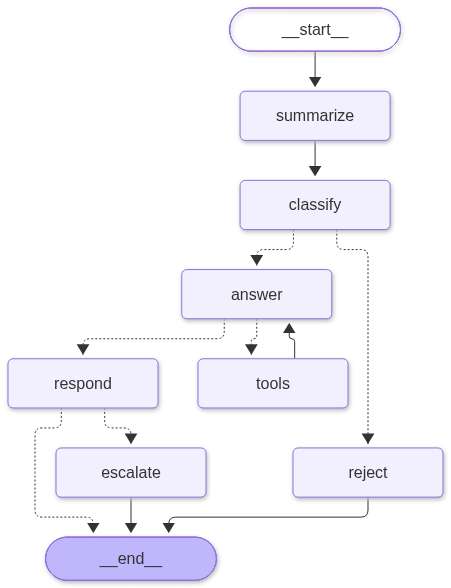

In [30]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

Eine Entschädigungsforderung. `ask` gäbe hier nur den Entwurf zurück, deshalb rufen wir
`graph.invoke` direkt auf:

In [31]:
config = {"configurable": {"thread_id": "chat-4"}}
question = "Mein Flug wurde annulliert. Ich verlange die 600 Euro Entschädigung."
result = graph.invoke({"messages": [HumanMessage(content=question)]}, config,
                      context={"user_id": "kunde-42"})

print("Entwurf:", result["__interrupt__"][0].value["entwurf"])
print("nächster Knoten:", graph.get_state(config).next)

Entwurf: Ich bin ein Prototyp aus einer Lehrveranstaltung und kein offizieller Dienst von SWISS. Eine Entschädigung von 600 € kommt grundsätzlich nur bei einer Flugstrecke über 3.500 km in Betracht; außerdem gelten weitere Voraussetzungen, und außergewöhnliche Umstände oder eine rechtzeitige Information können den Anspruch ausschließen. Bitte nennen Sie mir Abflug- und Zielflughafen, Flugdatum, wann Sie über die Annullierung informiert wurden, den angegebenen Grund sowie eine allfällige Ersatzbeförderung, damit ich Ihren Anspruch prüfen kann. Grundlage: SWISS-Unterlage «EU Regulation 261/04: your rights as a passenger».
nächster Knoten: ('escalate',)


Der Graph steht vor `escalate`. Die Mitarbeiterin antwortet mit `Command(resume=...)`:
Ihr Text wird zum Rückgabewert von `interrupt()`, und der Graph läuft weiter. Hier ein
fester Text; in einer Anwendung käme er aus einem Eingabefeld.

In [32]:
reply = "Wir prüfen Ihren Anspruch nach EU 261 und melden uns innerhalb von fünf Arbeitstagen."
result = graph.invoke(Command(resume=reply), config)

print(result["response"].answer)
print("nächster Knoten:", graph.get_state(config).next)

Wir prüfen Ihren Anspruch nach EU 261 und melden uns innerhalb von fünf Arbeitstagen.
nächster Knoten: ()


**Beim Fortsetzen läuft `escalate` von vorn**, bis zu `interrupt()`, das jetzt den Text
zurückgibt. Was vor `interrupt()` steht, läuft also zweimal. Dort darf nichts stehen, was
nicht doppelt passieren darf, etwa eine E-Mail oder eine Buchung.

Zum Schluss lernt `ask`, dass der Graph anhalten kann. Auch eine Umbuchung braucht jetzt
einen Menschen:

In [33]:
def ask(question, thread_id="demo", user_id="gast"):
    config = {"configurable": {"thread_id": thread_id}}
    result = graph.invoke({"messages": [HumanMessage(content=question)]}, config,
                          context={"user_id": user_id})
    if "__interrupt__" in result:
        return "Wartet auf eine Mitarbeiterin. Entwurf: " + result["__interrupt__"][0].value["entwurf"]
    return result["response"].answer


print(ask("Bitte buchen Sie meinen Flug auf morgen um.", thread_id="chat-5", user_id="kunde-42"))

Wartet auf eine Mitarbeiterin. Entwurf: Gerne – ich bin jedoch ein Prototyp aus einer Lehrveranstaltung und kann keine Umbuchung direkt durchführen. Bitte nennen Sie mir Ihre Buchungsnummer, die Strecke sowie den gewünschten Flug am 10. November 2026. Dann kann ich die Bedingungen für Ihren Economy-Flex-Tarif prüfen.


## Aufgaben bis zur nächsten Woche:

- **Gespräch:** Führt mit eurem Agenten ein Gespräch über drei Fragen, in dem sich die
  dritte auf die erste bezieht. Wo geht etwas verloren?
- **Verlauf:** Schaut euch mit `get_state_history` an, welche Knoten in welcher
  Reihenfolge gelaufen sind, und vergleicht mit dem Trace in LangSmith.
- **Trimmen:** Setzt `MAX_TOKENS` auf 300 und auf 5000. Was vergisst der Agent? Was
  passiert bei 300 mit einer Frage, für die er in den Unterlagen sucht?
- **Zusammenfassung:** Lest die `summary` von `kunde-4`. Was ist drin, was fehlt? Ändert
  `SUMMARY_PROMPT` so, dass etwas anderes erhalten bleibt.
- **Langzeitgedächtnis:** Was soll euer Agent über ein Gespräch hinaus wissen? Wählt
  ein Feld und speichert es im Store.
- **Mensch:** Wo muss in eurem Projekt ein Mensch entscheiden? Baut dort ein
  `interrupt()` ein.

### Für euer Projekt

- **Gedächtnis:** Braucht euer Agent ein Gedächtnis pro Gespräch, eines über Gespräche
  hinweg oder beides? Begründet eure Entscheidung in 2–3 Sätzen.

## Baustein zum Mitnehmen

In [34]:
import warnings
from langchain_core.messages.utils import count_tokens_approximately, trim_messages
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.memory import InMemoryStore
from langgraph.runtime import Runtime
from langgraph.types import interrupt, Command

warnings.filterwarnings("ignore", message="Pydantic serializer warnings")

CLASSIFY_PROMPT = """Entscheide, ob die letzte Nachricht im Gespräch zu einem Assistenten für SWISS International Air Lines gehört, und bestimme ihr Thema.
Beurteile sie im Zusammenhang der vorherigen Nachrichten: Eine kurze Nachfrage gehört zum selben Thema.
Zuständig: Flüge, Tarife, Gepäck, Buchung, Umbuchung, Erstattung bei SWISS, Fragen an den Assistenten.
Nicht zuständig: andere Fluggesellschaften und alles andere."""

SUMMARY_PROMPT = """Fasse das Gespräch zwischen einer Kundin oder einem Kunden und dem SWISS-Assistenten in wenigen Sätzen zusammen.
Behalte, was für spätere Fragen wichtig ist, etwa den Tarif oder die Reise."""

checkpointer = InMemorySaver()
memory_store = InMemoryStore()
MAX_TOKENS = 1300


def summarize(state: AgentState):
    questions = [i for i, m in enumerate(state["messages"]) if m.type == "human"]
    if len(questions) < 2:
        return {}
    last_round = state["messages"][questions[-2]:questions[-1]]
    text = "\n".join(f"{m.type}: {m.content}" for m in last_round)
    prompt = (f"{SUMMARY_PROMPT}\n\nBisherige Zusammenfassung:\n{state.get('summary', '')}"
              f"\n\nNeue Runde:\n{text}")
    return {"summary": llm.invoke(prompt).content}


def classify(state: AgentState):
    result = classifier.invoke([SystemMessage(content=CLASSIFY_PROMPT)] + state["messages"])
    return {"in_scope": result.in_scope, "category": result.category}


def answer(state: AgentState, runtime: Runtime):
    prompt = SYSTEM_PROMPT
    if state.get("summary"):
        prompt += f"\nBisheriges Gespräch, zusammengefasst: {state['summary']}"
    profile = runtime.store.get((runtime.context["user_id"], "profile"), "fare")
    if profile:
        prompt += f"\nAus früheren Gesprächen bekannt: Die Person fliegt {profile.value['fare']}."
    recent = trim_messages(state["messages"], strategy="last", max_tokens=MAX_TOKENS,
                           token_counter=count_tokens_approximately, start_on="human")
    return {"messages": [llm_with_tools.invoke([SystemMessage(content=prompt)] + recent)]}


def respond(state: AgentState, runtime: Runtime):
    messages = ([SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
                + [HumanMessage(content="Übernimm deine letzte Antwort unverändert in das vorgegebene Format.")])
    response = responder.invoke(messages)
    if response.fare:
        runtime.store.put((runtime.context["user_id"], "profile"), "fare", {"fare": response.fare})
    return {"response": response}


def escalate(state: AgentState):
    reply = interrupt({"entwurf": state["response"].answer})
    response = AgentResponse(answer=reply, fare=state["response"].fare, needs_human=True)
    return {"messages": [AIMessage(content=reply)], "response": response}


def route_after_respond(state: AgentState):
    return "escalate" if state["response"].needs_human else END


def build_graph(checkpointer=None, store=None):
    builder = StateGraph(AgentState)
    builder.add_node("summarize", summarize)
    builder.add_node("classify", classify)
    builder.add_node("reject", reject)
    builder.add_node("answer", answer)
    builder.add_node("tools", call_tools,
                     retry_policy=RetryPolicy(max_attempts=3, retry_on=ConnectionError))
    builder.add_node("respond", respond)
    builder.add_node("escalate", escalate)
    builder.add_edge(START, "summarize")
    builder.add_edge("summarize", "classify")
    builder.add_conditional_edges("classify", route_after_classify, ["answer", "reject"])
    builder.add_edge("reject", END)
    builder.add_conditional_edges("answer", route_after_answer, ["tools", "respond"])
    builder.add_edge("tools", "answer")
    builder.add_conditional_edges("respond", route_after_respond, ["escalate", END])
    builder.add_edge("escalate", END)
    return builder.compile(checkpointer=checkpointer, store=store)


graph = build_graph(checkpointer=checkpointer, store=memory_store)


def ask(question, thread_id="demo", user_id="gast"):
    config = {"configurable": {"thread_id": thread_id}}
    result = graph.invoke({"messages": [HumanMessage(content=question)]}, config,
                          context={"user_id": user_id})
    if "__interrupt__" in result:
        return "Wartet auf eine Mitarbeiterin. Entwurf: " + result["__interrupt__"][0].value["entwurf"]
    return result["response"].answer